# K-Means Clustering Using Mall Customer Dataset

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

## Create the Dataset

In [2]:
# Mall customer data
# Features: Annual Income and Spending Score

X = np.array([
    [15, 39],
    [16, 42],
    [18, 45],
    [20, 48],
    [22, 50],
    [25, 55],
    [60, 60],
    [62, 65],
    [65, 70],
    [70, 75],
    [85, 20],
    [90, 25],
    [95, 30],
    [100, 35],
    [105, 40]
])

print("Dataset shape:", X.shape)

Dataset shape: (15, 2)


 ## Standardize the Data

In [3]:
# Standardize the customer data

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Standardized Data:")
print(X_scaled)

Standardized Data:
[[-1.25925157 -0.48616835]
 [-1.22893251 -0.29425979]
 [-1.16829439 -0.10235123]
 [-1.10765628  0.08955733]
 [-1.04701816  0.21749637]
 [-0.95606098  0.53734397]
 [ 0.10510607  0.85719157]
 [ 0.16574419  1.17703917]
 [ 0.25670136  1.49688677]
 [ 0.40829666  1.81673437]
 [ 0.86308254 -1.70158924]
 [ 1.01467783 -1.38174164]
 [ 1.16627312 -1.06189404]
 [ 1.31786842 -0.74204643]
 [ 1.46946371 -0.42219883]]


##  Apply the Elbow Method

In [4]:
# Calculate inertia for different values of K

inertia = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    inertia.append(model.inertia_)

## Plot the Elbow Graph

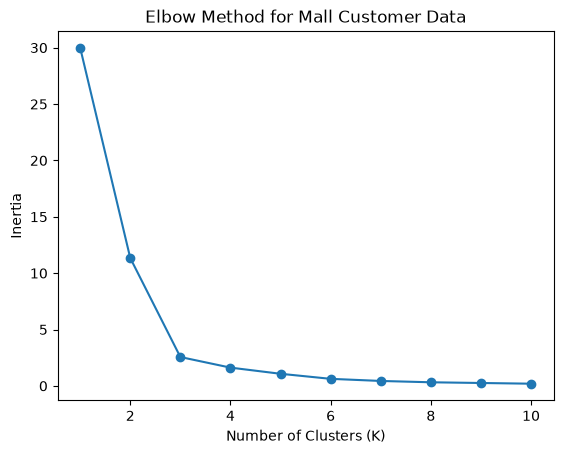

In [5]:
# Visualize the Elbow Method

plt.plot(range(1, 11), inertia, marker='o')
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Mall Customer Data")
plt.show()

## Apply K-Means with K = 3

In [6]:
# Divide customers into three clusters

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

clusters = kmeans.fit_predict(X_scaled)

print("Cluster Labels:")
print(clusters)

Cluster Labels:
[2 2 2 2 2 2 0 0 0 0 1 1 1 1 1]


## Visualize the Clusters

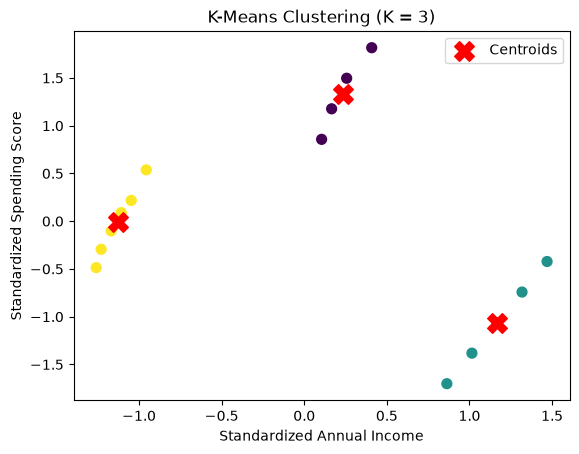

In [7]:
# Display customer clusters

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=clusters,
    cmap='viridis',
    s=50
)

# Display cluster centroids

plt.scatter(
    kmeans.cluster_centers_[:, 0],
    kmeans.cluster_centers_[:, 1],
    marker='X',
    s=200,
    color='red',
    label='Centroids'
)

plt.xlabel("Standardized Annual Income")
plt.ylabel("Standardized Spending Score")
plt.title("K-Means Clustering (K = 3)")
plt.legend()
plt.show()

## Display Cluster Assignments

In [8]:
# Print each customer's cluster number

print("\nFirst 10 Customer Cluster Assignments:")

for i in range(10):
    print(
        "Customer", i + 1,
        "- Annual Income:", X[i][0],
        "- Spending Score:", X[i][1],
        "- Cluster:", clusters[i]
    )


First 10 Customer Cluster Assignments:
Customer 1 - Annual Income: 15 - Spending Score: 39 - Cluster: 2
Customer 2 - Annual Income: 16 - Spending Score: 42 - Cluster: 2
Customer 3 - Annual Income: 18 - Spending Score: 45 - Cluster: 2
Customer 4 - Annual Income: 20 - Spending Score: 48 - Cluster: 2
Customer 5 - Annual Income: 22 - Spending Score: 50 - Cluster: 2
Customer 6 - Annual Income: 25 - Spending Score: 55 - Cluster: 2
Customer 7 - Annual Income: 60 - Spending Score: 60 - Cluster: 0
Customer 8 - Annual Income: 62 - Spending Score: 65 - Cluster: 0
Customer 9 - Annual Income: 65 - Spending Score: 70 - Cluster: 0
Customer 10 - Annual Income: 70 - Spending Score: 75 - Cluster: 0
